# Notebook showing a fast and efficient way to load Sentinel-2 L1C data into xarray

In [22]:
import glob
import os
import numpy as np

import pandas as pd
import geopandas as gpd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap

from GRSdriver import driver_S2_SAFE as S2
from GRSdriver import visual

opj = os.path.join


Set the path of the images you want to load, here is a example for the former (v3) and current (v4) image formatting 

In [23]:
imageSAFE = '/data/satellite/Sentinel-2/L1C/28PBB/2022/02/11/S2A_MSIL1C_20220211T113321_N0510_R080_T28PBB_20240513T102419.SAFE'

#imageSAFE = '/data/satellite/Sentinel-2/L1C/55WFU/2021/07/30/S2B_MSIL1C_20210730T015659_N0500_R060_T55WFU_20230123T110212.SAFE/'




First, check the availbale bands:

In [24]:
S2.INFO

bandId,0,1,2,3,4,5,6,7,8,9,10,11,12
ESA,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
EOREADER,CA,BLUE,GREEN,RED,VRE_1,VRE_2,VRE_3,NIR,NARROW_NIR,WV,SWIR_CIRRUS,SWIR_1,SWIR_2
Wavelength (nm),443,490,560,665,705,740,783,842,865,945,1375,1610,2190
Band width (nm),20,65,35,30,15,15,20,115,20,20,30,90,180
Resolution (m),60,10,10,10,20,20,20,10,20,60,60,20,20


Choose the bands to be loaded (fill the bandIds array up) and the resolution between 10, 20 and 60 m:

In [45]:
bandIds = range(13) #[0,1,2,3,4,8,11,12]
#bandIds = [1,2,3,4,7,11]
resolution=60


Create the s2driver objects for the selected images

In [46]:

l1c = S2.Sentinel2Driver(imageSAFE,band_idx=bandIds,resolution=resolution)
ESAbands = l1c.INFO.loc['ESA']
ESAbands.values

array(['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A',
       'B09', 'B10', 'B11', 'B12'], dtype=object)

In [47]:
import eoreader
reader = eoreader.reader.Reader()

# Open the product
reader = reader.open(imageSAFE)
reader

eoreader.S2Product 'S2A_MSIL1C_20220211T113321_N0510_R080_T28PBB_20240513T102419'
Attributes:
	condensed_name: 20220211T113321_S2_T28PBB_L1C_102419
	path: /data/satellite/Sentinel-2/L1C/28PBB/2022/02/11/S2A_MSIL1C_20220211T113321_N0510_R080_T28PBB_20240513T102419.SAFE
	constellation: Sentinel-2
	sensor type: Optical
	product type: MSIL1C
	default pixel size: 10.0
	default resolution: 10.0
	acquisition datetime: 2022-02-11T11:33:21
	band mapping:
		COASTAL_AEROSOL: 01
		BLUE: 02
		GREEN: 03
		RED: 04
		VEGETATION_RED_EDGE_1: 05
		VEGETATION_RED_EDGE_2: 06
		VEGETATION_RED_EDGE_3: 07
		NIR: 08
		NARROW_NIR: 8A
		WATER_VAPOUR: 09
		SWIR_CIRRUS: 10
		SWIR_1: 11
		SWIR_2: 12
	needs extraction: False
	cloud cover: 0.0
	tile name: T28PBB

In [48]:
l1c.INFO


bandId,0,1,2,3,4,5,6,7,8,9,10,11,12
ESA,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
EOREADER,CA,BLUE,GREEN,RED,VRE_1,VRE_2,VRE_3,NIR,NARROW_NIR,WV,SWIR_CIRRUS,SWIR_1,SWIR_2
Wavelength (nm),443,490,560,665,705,740,783,842,865,945,1375,1610,2190
Band width (nm),20,65,35,30,15,15,20,115,20,20,30,90,180
Resolution (m),60,10,10,10,20,20,20,10,20,60,60,20,20


Load band reflectances and get the *bands* xarray 


In [49]:
l1c.load_bands(add_time=True)

/home/harmel/anaconda3/envs/grstbx/lib/python3.9/site-packages/xarray/core/indexes.py:659: RuntimeWarning: '<' not supported between instances of 'SpectralBandNames' and 'SpectralBandNames', sort order is undefined for incomparable objects.
  new_pd_index = pd_indexes[0].append(pd_indexes[1:])


In [50]:
l1c.prod

<xarray.Dataset>
Dimensions:      (x: 1830, y: 1830, wl: 13, wl_hr: 1950)
Coordinates:
  * x            (x) float64 2e+05 2.001e+05 2.001e+05 ... 3.097e+05 3.098e+05
  * y            (y) float64 1.7e+06 1.7e+06 1.7e+06 ... 1.59e+06 1.59e+06
    spatial_ref  int64 0
  * wl           (wl) object 443 490 560 665 705 740 ... 865 945 1375 1610 2190
  * wl_hr        (wl_hr) int64 400 401 402 403 404 ... 2345 2346 2347 2348 2349
    time         datetime64[ns] 2022-02-11T11:33:21
Data variables:
    bands        (wl, y, x) float32 0.1313 0.1316 0.1315 ... 0.4326 0.4108
    SRF          (wl, wl_hr) float64 nan nan nan nan nan ... nan nan nan nan nan
    wl_true      (wl) float64 442.7 492.7 559.9 ... 1.614e+03 2.202e+03
Attributes: (12/14)
    long_name:         CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 NIR NARROW_NIR WV ...
    constellation:     Sentinel-2
    constellation_id:  S2
    product_path:      /data/satellite/Sentinel-2/L1C/28PBB/2022/02/11/S2A_MS...
    product_name:      S2A_MSIL1C_20220211T113321_N0510_R080_T28PBB_20240513T...
    product_filename:  S2A_MSIL1C_20220211T113321_N0510_R080_T28PBB_20240513T...
    ...                ...
    acquisition_date:  20220211T113321
    condensed_name:    20220211T113321_S2_T28PBB_L1C_102419
    orbit_direction:   DESCENDING
    radiometry:        reflectance
    cloud_cover:       0.0
    wl_to_process:     [ 443  490  560  665  705  740  783  842  865 1610 2190]

In [53]:

wl_ave=0
norm=0
for wl in [490,560,665,705,740]:#[490,560,705]:#
    band = l1c.prod.sel(wl=wl,method='nearest')
    wl_ave += band.bands*band.wl_true
    norm += band.bands
wl_ave=wl_ave/norm

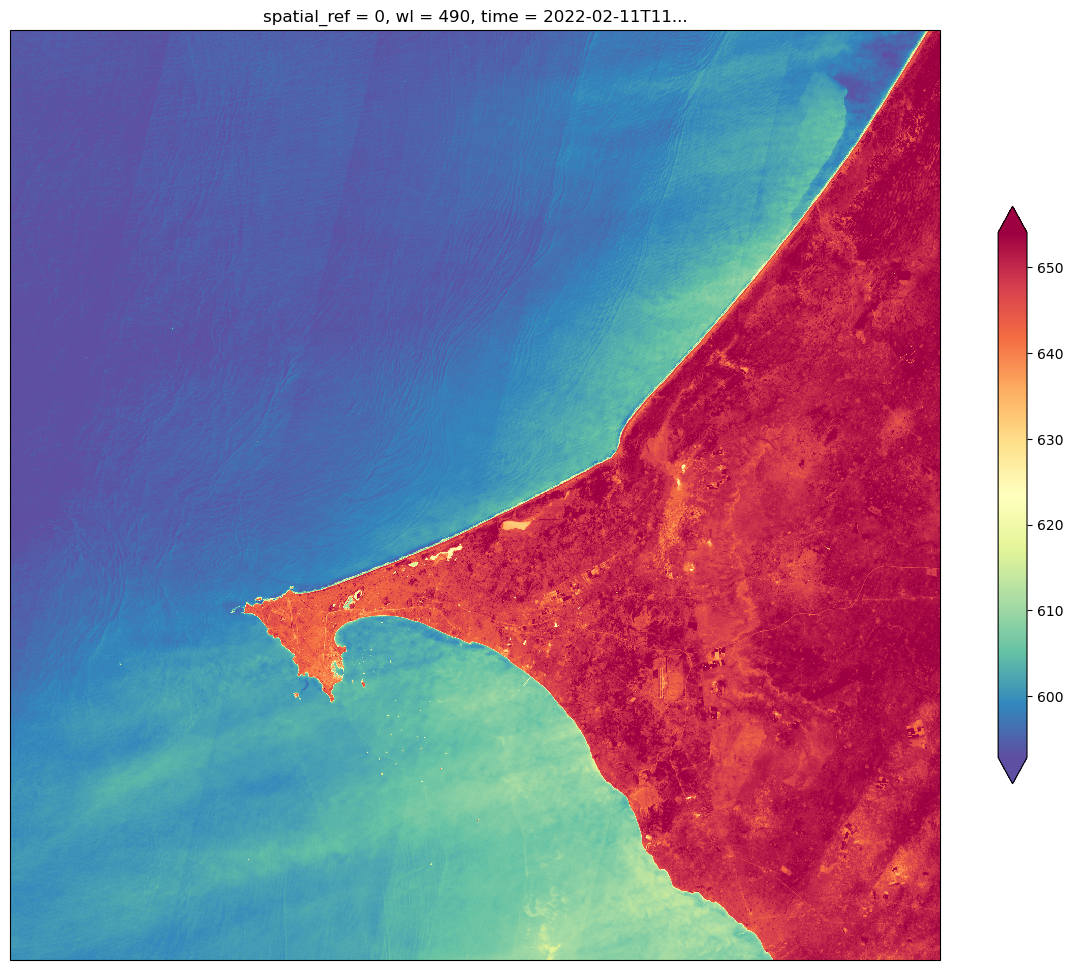

In [54]:

str_epsg = str(l1c.prod.bands.rio.crs)
zone = str_epsg[-2:]
is_south = str_epsg[2] == 7
proj = ccrs.UTM(zone, is_south)

plt.figure(figsize=(15,15))
fig = wl_ave.plot.imshow(cmap=plt.cm.Spectral_r, robust=True,subplot_kws=dict(projection=proj),cbar_kwargs={'shrink':0.5})

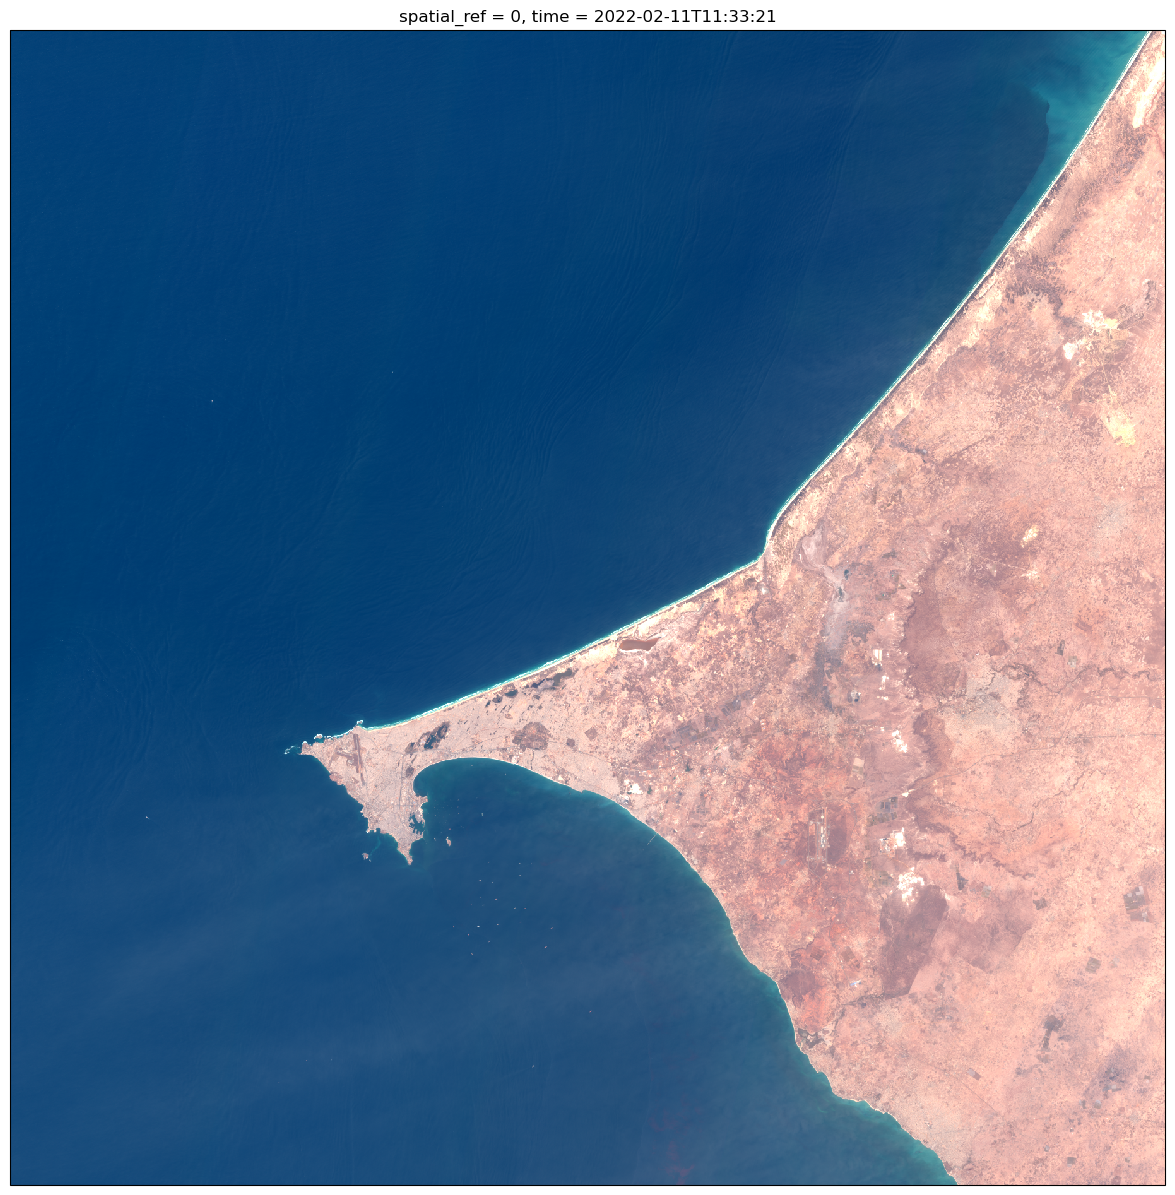

In [55]:

str_epsg = str(l1c.prod.bands.rio.crs)
zone = str_epsg[-2:]
is_south = str_epsg[2] == 7
proj = ccrs.UTM(zone, is_south)

plt.figure(figsize=(15,15))
fig = (l1c.prod.bands.sel(wl=[705,560,490])**0.2).plot.imshow(rgb='wl', robust=True,subplot_kws=dict(projection=proj))

# Plotting section
The MSI-Sentinel-2 instrument is composed of 12 detectors staggered in two different rows making a "switch" in viewng geometries along the image especially for the azimuth values. Here, we plot the solar and viewing zenith angles as well as the relative azimuth between Sun and sensor directions.
The sun viewing angle (SZA) is common to all the spectral bands.

Set 'reproject=True' to repoject raster into WGS 84 / Pseudo-Mercator for web mapping and visualization (e.g., OpenStreetMap). The EPSG code is 3857. 

In [56]:
h=visual.ViewSpectral(l1c.prod.bands,reproject=True)#.assign_coords(time=l1c.datetime).expand_dims('time')

In [57]:
 # h.colormaps = ['CET_D13', 'bky', 'CET_D1A','CET_CBL2','CET_L10','CET_C6s', 'kbc', 'blues_r', 'kb', 'rainbow', 'fire', 'kgy', 'bjy','gray' ]

In [58]:
h.visu()

Column
    [0] WidgetBox
        [0] Markdown(str)
        [1] Column
            [0] Row
                [0] Markdown(str)
                [1] RadioButtonGroup(options=[0, 1, 2, 3, 4, ...], value=0)
            [1] Row
                [0] Row
                    [0] Markdown(str)
                    [1] DatePicker(enabled_dates=[datetime.date(2022, ...], start=datetime.date(2022, ..., value=datetime.date(2022, ...)
                [1] Row
                    [0] Markdown(str)
                    [1] Select(options=['CartoDark', ...], value='CartoDark')
            [2] Row
                [0] Row
                    [0] Markdown(str)
                    [1] EditableRangeSlider(name='Range Slider', step=0.001, value=(0, 0.5), width=300)
                [1] Row
                    [0] Markdown(str)
                    [1] FloatSlider(name='Opacity', step=0.05, value=0.95)
                [2] Row
                    [0] Markdown(str)
                    [1] Select(options=['CET_D13', 'bky', ...], value='CET_D13')
        [2] HoloViews(DynamicMap, height=800, sizing_mode='fixed', width=1200)

In [37]:
geom_ = h.get_geom(h.aoi_stream,crs=l1c.prod.rio.crs)

Rtoa_clipped = l1c.prod.bands.rio.clip(geom_.geometry.values)

IndexError: list index out of range

In [16]:
l1c.prod

<xarray.Dataset>
Dimensions:      (x: 1830, y: 1830, wl: 6, wl_hr: 1950)
Coordinates:
  * x            (x) float64 5e+05 5.001e+05 5.001e+05 ... 6.097e+05 6.098e+05
  * y            (y) float64 5.3e+06 5.3e+06 5.3e+06 ... 5.19e+06 5.19e+06
    spatial_ref  int64 0
  * wl           (wl) object 490 560 665 705 842 1610
  * wl_hr        (wl_hr) int64 400 401 402 403 404 ... 2345 2346 2347 2348 2349
    time         datetime64[ns] 2019-06-21T11:06:21
Data variables:
    bands        (wl, y, x) float32 0.09526 0.0953 0.0949 ... 0.1532 0.1647
    SRF          (wl, wl_hr) float64 nan nan nan nan nan ... nan nan nan nan nan
    wl_true      (wl) float64 492.7 559.9 664.6 704.1 832.8 1.614e+03
Attributes: (12/14)
    long_name:         BLUE GREEN RED VRE_1 NIR SWIR_1
    constellation:     Sentinel-2
    constellation_id:  S2
    product_path:      /data/satellite/Sentinel-2/L1C/30TWT/2019/06/21/S2A_MS...
    product_name:      S2A_MSIL1C_20190621T110621_N0500_R137_T30TWT_20230609T...
    product_filename:  S2A_MSIL1C_20190621T110621_N0500_R137_T30TWT_20230609T...
    ...                ...
    acquisition_date:  20190621T110621
    condensed_name:    20190621T110621_S2_T30TWT_L1C_074614
    orbit_direction:   DESCENDING
    radiometry:        reflectance
    cloud_cover:       32.8840216190391
    wl_to_process:     [ 443  490  560  665  705  740  783  842  865 1610 2190]

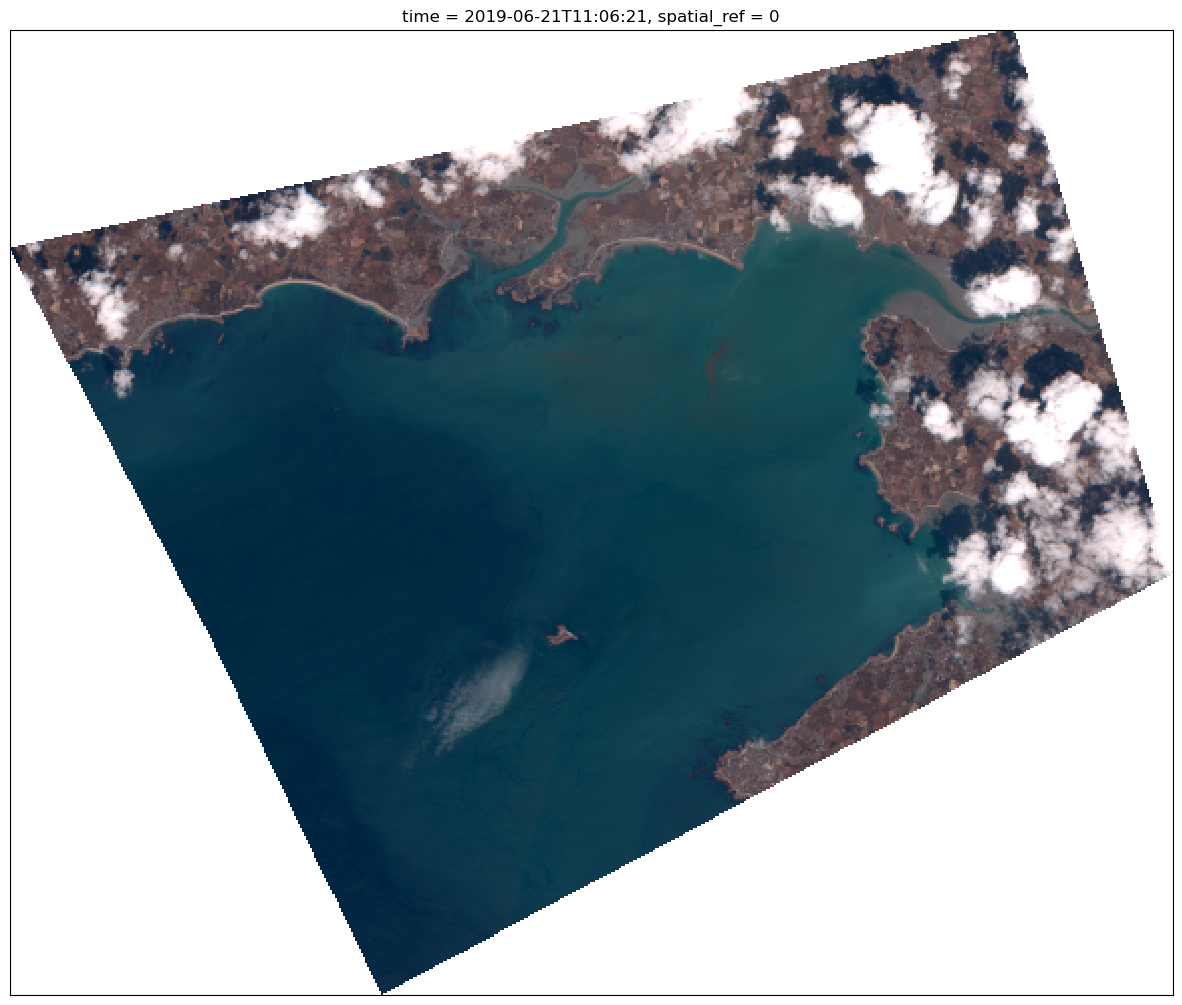

In [19]:

#%matplotlib ipympl
import cartopy.crs as ccrs
str_epsg = str(l1c.prod.bands.rio.crs)
zone = str_epsg[-2:]
is_south = str_epsg[2] == 7
proj = ccrs.UTM(zone, is_south)

plt.figure(figsize=(15,15))
fig = (Rtoa_clipped.sel(wl=[705,560,490])**0.3).plot.imshow(rgb='wl', robust=True,subplot_kws=dict(projection=proj))

In [19]:
#geom_.to_file("/data/test/roi_batumi.json", driver="GeoJSON")

In [18]:
#fig.figure.savefig('/data/test/subset.png')

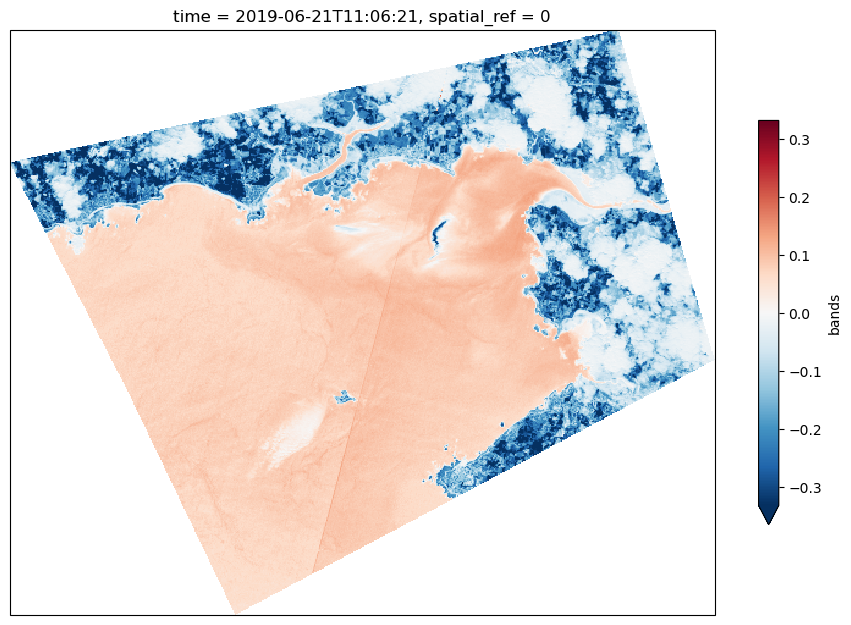

In [21]:

red = Rtoa_clipped.sel(wl=705,method='nearest')
nir = Rtoa_clipped.sel(wl=865,method='nearest')
visible = Rtoa_clipped.sel(wl=670,method='nearest')
swir = Rtoa_clipped.sel(wl=2200,method='nearest')

ndwi = (visible - red) / (visible +red)
ndwi_swir = (visible - swir) / (visible + swir)

fig = plt.figure(figsize=(25, 15))
ax = plt.subplot(1, 2, 1, projection=proj)
ndwi.plot.imshow(robust=True,subplot_kws=dict(projection=proj),cbar_kwargs={'shrink':0.35})

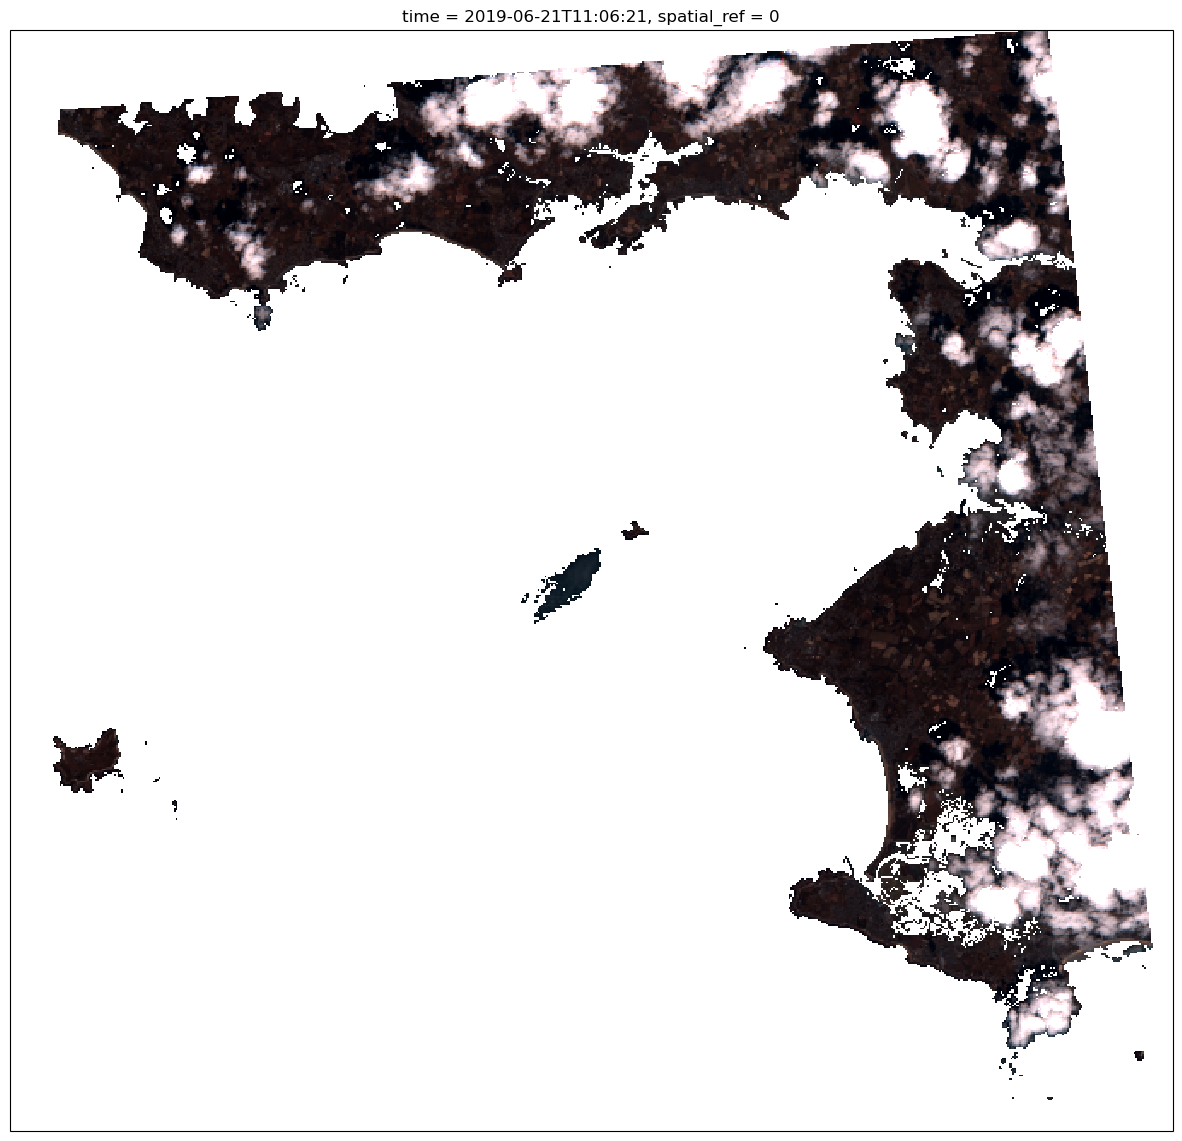

In [30]:
mask =  (ndwi_swir < 0.1) 
masked = Rtoa_clipped.where(mask)


plt.figure(figsize=(15,15))
masked.sel(wl=[705,560,490]).plot.imshow(rgb='wl', robust=True,subplot_kws=dict(projection=proj))

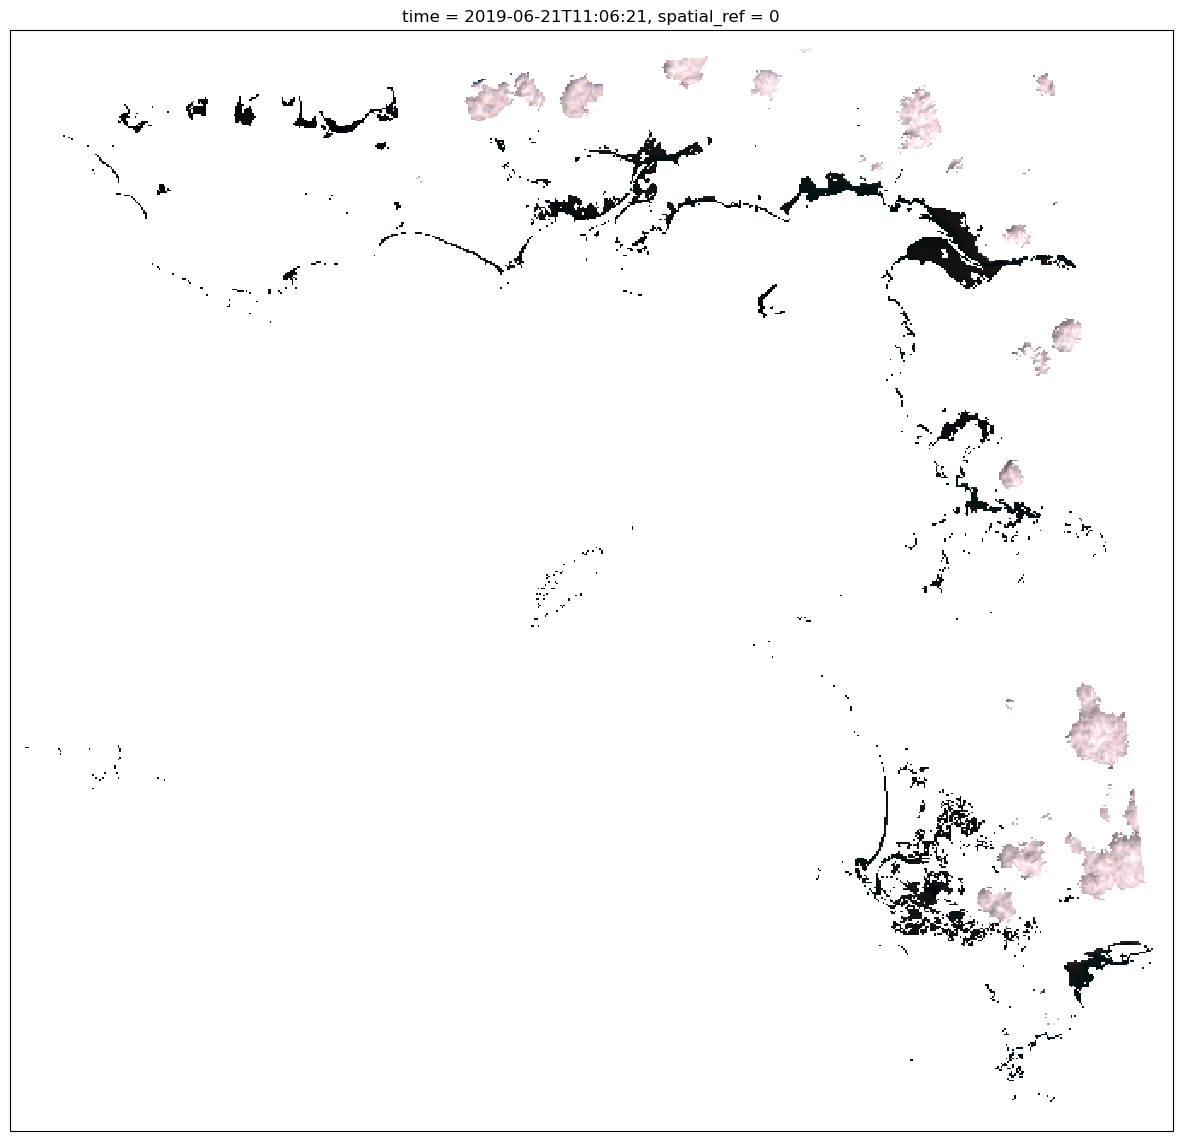

In [45]:
mask =  (ndwi_swir > 0.12) 
masked = Rtoa_clipped.where(mask)


plt.figure(figsize=(15,15))
masked.sel(wl=[705,560,490]).where(masked.sel(wl=705)>0.065).plot.imshow(rgb='wl', robust=True,subplot_kws=dict(projection=proj))

In [32]:
h=visual.ViewSpectral(masked,reproject=True)
h.visu()

Column
    [0] WidgetBox
        [0] Markdown(str)
        [1] Column
            [0] Row
                [0] Markdown(str)
                [1] RadioButtonGroup(options=[0, 1, 2, 3, 4, 5], value=0)
            [1] Row
                [0] Row
                    [0] Markdown(str)
                    [1] DatePicker(enabled_dates=[datetime.date(2019, ...], start=datetime.date(2019, ..., value=datetime.date(2019, ...)
                [1] Row
                    [0] Markdown(str)
                    [1] Select(options=['CartoDark', ...], value='CartoDark')
            [2] Row
                [0] Row
                    [0] Markdown(str)
                    [1] EditableRangeSlider(name='Range Slider', step=0.001, value=(0, 0.5), width=300)
                [1] Row
                    [0] Markdown(str)
                    [1] FloatSlider(name='Opacity', step=0.05, value=0.95)
                [2] Row
                    [0] Markdown(str)
                    [1] Select(options=['CET_D13', 'bky', ...], value='CET_D13')
        [2] HoloViews(DynamicMap, height=800, sizing_mode='fixed', width=1200)

In [43]:
ncols=2
nrows=4
#coarsening to save memory and speed
coarsening=5
sunglint_threshold = 0.2
ndwi_threshold = 0.01
green_swir_index_threshold = 0.1
hcld_threshold = 3e-3

# Get geographic projection and bounds
#extent = prod.extent
#proj = prod.proj
#bounds = extent.bounds
#extent_val = [bounds.minx[0]+20000, bounds.maxx[0]-3000, bounds.miny[0], bounds.maxy[0]-50000]

# binary cmap
bcmap = ListedColormap(['khaki', 'lightblue'])


def water_mask(ndwi, threshold=0):
    water = xr.where(ndwi > threshold, 1, 0)
    return water.where(~np.isnan(ndwi))

def plot_water_mask(ndwi,ax,threshold=0):
    water = water_mask(ndwi, threshold)
    ax.set_extent(extent_val, proj)
    water.plot.imshow(extent=extent_val, transform=proj, cmap=bcmap,
                                  cbar_kwargs={'ticks': [0, 1], 'shrink': shrink})
    ax.set_title(str(threshold)+' < NDWI')

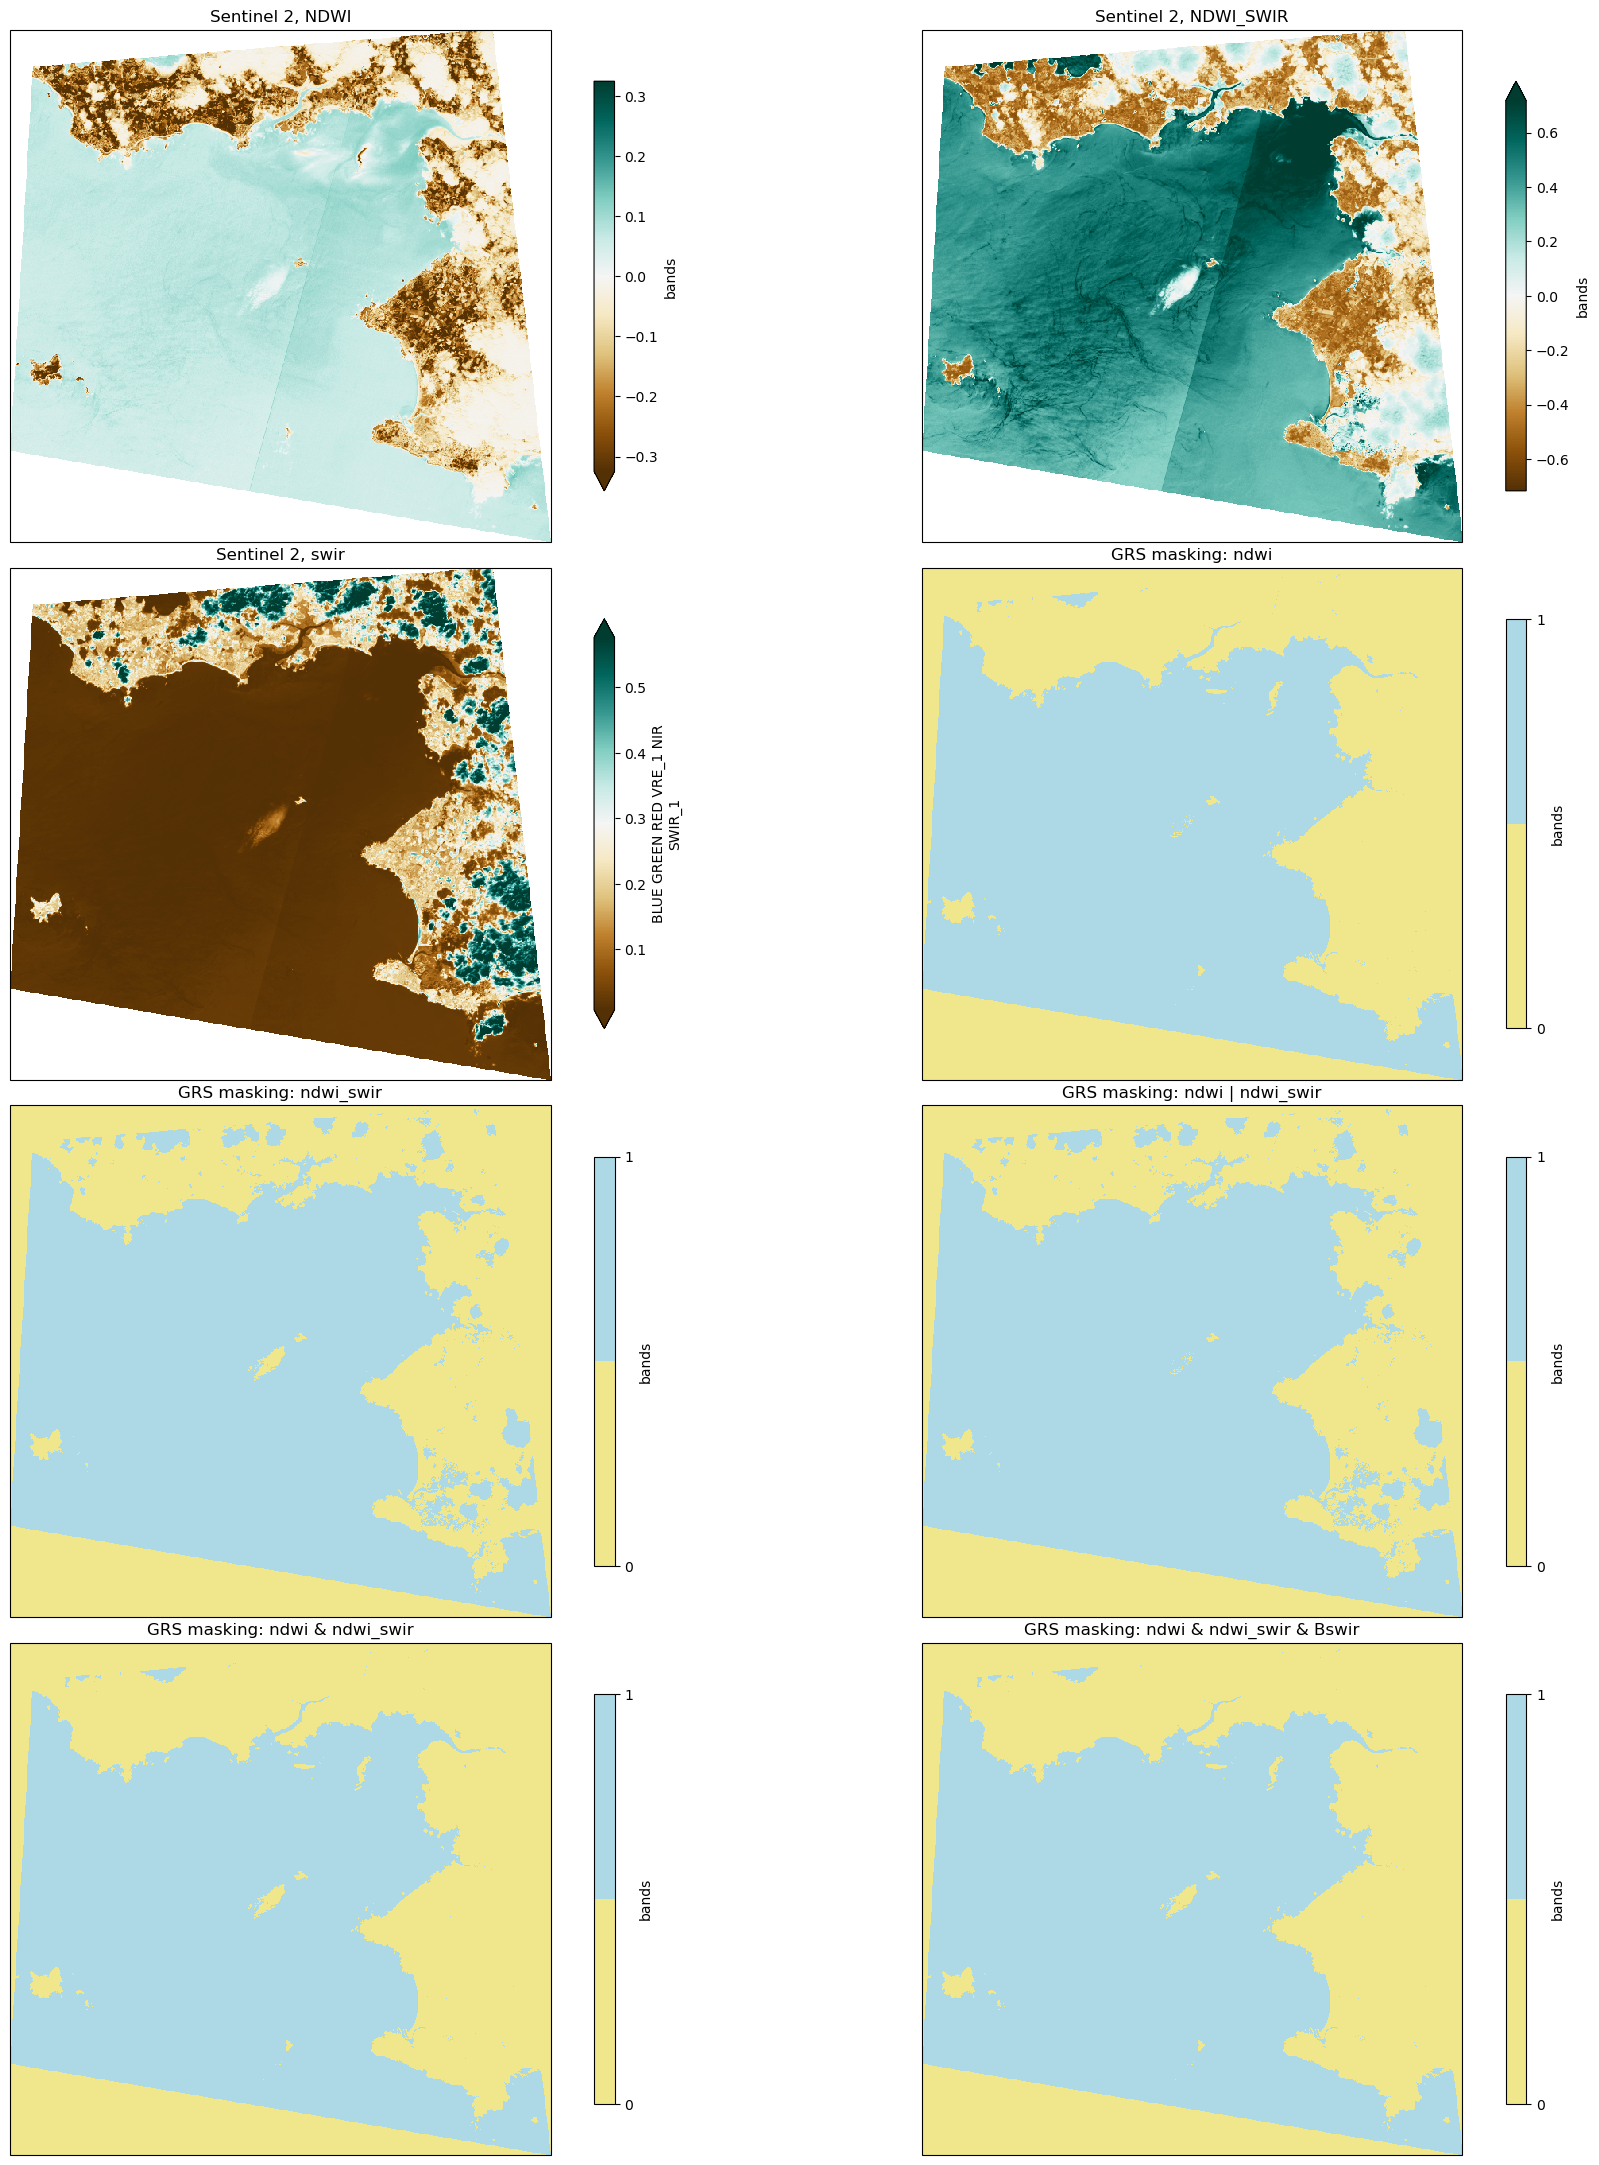

In [44]:
coarsening=1
fig = plt.figure(figsize=(20, 25))
fig.subplots_adjust(bottom=0.1, top=0.95, left=0.1, right=0.99,
                    hspace=0.05, wspace=0.05)
shrink = 0.8
ii=1
# NDWI    
ax = plt.subplot(nrows,ncols, ii, projection=proj)

fig = ndwi[::coarsening, ::coarsening].plot.imshow( transform=proj, cmap=plt.cm.BrBG, robust=True,
                                   cbar_kwargs={'shrink': shrink})
ax.set_title('Sentinel 2, NDWI')
ii+=1

# NDWI_SWIR    
ax = plt.subplot(nrows,ncols, ii, projection=proj)

fig = ndwi_swir[::coarsening, ::coarsening].plot.imshow( transform=proj, cmap=plt.cm.BrBG, robust=True,
                                   cbar_kwargs={'shrink': shrink})
ax.set_title('Sentinel 2, NDWI_SWIR')
ii+=1


# swir
ax = plt.subplot(nrows,ncols, ii, projection=proj)

fig = swir[::coarsening, ::coarsening].plot.imshow(transform=proj, cmap=plt.cm.BrBG, robust=True,
                                   cbar_kwargs={'shrink': shrink})
ax.set_title('Sentinel 2, swir')
ii+=1


ax = plt.subplot(nrows,ncols, ii, projection=proj)
water = xr.where((ndwi > ndwi_threshold),1,0) # &  

water.plot.imshow(transform=proj, cmap=bcmap,
                              cbar_kwargs={'ticks': [0, 1], 'shrink': shrink})
ax.set_title('GRS masking: ndwi')
ii+=1


ax = plt.subplot(nrows,ncols, ii, projection=proj)
water = xr.where((ndwi_swir > green_swir_index_threshold),1,0) # &  

water.plot.imshow(transform=proj, cmap=bcmap,
                              cbar_kwargs={'ticks': [0, 1], 'shrink': shrink})
ax.set_title('GRS masking: ndwi_swir')
ii+=1



ax = plt.subplot(nrows,ncols, ii, projection=proj)
water = xr.where((ndwi > ndwi_threshold)| (ndwi_swir > green_swir_index_threshold),1,0) # &  

water.plot.imshow(transform=proj, cmap=bcmap,
                              cbar_kwargs={'ticks': [0, 1], 'shrink': shrink})
ax.set_title('GRS masking: ndwi | ndwi_swir')
ii+=1


ax = plt.subplot(nrows,ncols, ii, projection=proj)
water = xr.where(((ndwi > ndwi_threshold) & (ndwi_swir > green_swir_index_threshold)) ,1,0) # &  

water.plot.imshow(transform=proj, cmap=bcmap,
                              cbar_kwargs={'ticks': [0, 1], 'shrink': shrink})
ax.set_title('GRS masking: ndwi & ndwi_swir')
ii+=1


ax = plt.subplot(nrows,ncols, ii, projection=proj)
water = xr.where(((ndwi > ndwi_threshold)& (ndwi_swir > green_swir_index_threshold)) & (swir < sunglint_threshold),1,0) # &  

water.plot.imshow(transform=proj, cmap=bcmap,
                              cbar_kwargs={'ticks': [0, 1], 'shrink': shrink})
ax.set_title('GRS masking: ndwi & ndwi_swir & Bswir')

plt.show()